# SINTESI — Performance models (Roofline)

Dal capitolo del corso: *1.5 Performance models*. Concetti chiave per il ripasso rapido.

**Che cos'è un performance model**: lega le proprietà di un programma ai limiti della macchina. È una semplificazione, non un sostituto della misura. Serve a: stabilire un **bound**, capire **quale risorsa limita** (calcolo, memoria, comunicazione, parallelismo) e stimare se un'ottimizzazione ha **margine di guadagno**.

## 1. Intensità aritmetica (operational intensity)

$$I = \frac{N_{\mathrm{flop}}}{Q} \qquad [\text{flop/byte}]$$

- $N_{\mathrm{flop}}$ = numero di operazioni floating-point; $Q$ = byte trasferiti.
- "*Arithmetic intensity*" = stima algoritmica; "*operational intensity*" = traffico di una data implementazione. Intercambiabili, ma **va sempre dichiarato il livello di memoria** (L1, LLC, RAM): lo stesso kernel ha intensità diverse per ogni livello.
- L'intensità NON è solo proprietà della formula matematica: dipende da rappresentazione dati, ordine di accesso, riuso in cache, trasformazioni del compilatore, dimensione del problema.

### Esempi chiave

| Kernel | Conto | Intensità ideale |
|---|---|---|
| addizione vettoriale `c=a+b` | 1 flop, 24 byte (2 letture + 1 scrittura double) | $I \approx 1/24 \approx 0.042$ flop/byte |
| matmul $n\times n$ | $2n^3$ flop, $24n^2$ byte | $I \approx n/12$ flop/byte |

- La matmul cresce con $n$ **solo se l'implementazione realizza il riuso** (blocking su tile che stanno in cache). Ordini di loop ingenui ricaricano i dati dopo l'eviction.
- Il traffico reale può superare il minimo: es. store miss con write-allocate legge prima la cache line di destinazione. L'esempio è quindi un **lower bound** sul traffico / **upper bound** sull'intensità.

## 2. Il modello Roofline

Con picco aritmetico $P_{\max}$ e bandwidth sostenibile $B$, il tempo è limitato da:

$$T \geq \max\left(\frac{N_{\mathrm{flop}}}{P_{\max}},\ \frac{Q}{B}\right) \qquad\Rightarrow\qquad P \leq \min(P_{\max},\ B\,I)$$

- Unità: $\frac{\text{byte}}{\text{s}} \times \frac{\text{flop}}{\text{byte}} = \frac{\text{flop}}{\text{s}}$.
- Plot **log-log**: asse x = intensità (flop/byte), asse y = performance (flop/s).
- Tetto `BI` = retta crescente (pendenza 1); tetto $P_{\max}$ = retta orizzontale. Il minimo delle due forma il tetto.
- Il tetto è un **upper bound**, non una previsione: un punto misurato può stare sotto per dependency, accessi irregolari, vettorizzazione incompleta, parallelismo insufficiente, load imbalance, overhead.

## 3. Ridge point

$$I_{\mathrm{ridge}} = \frac{P_{\max}}{B}$$

Descrive il **bilanciamento della macchina** in flop/byte:

- kernel a **sinistra** della ridge: non può raggiungere il picco aritmetico → **memory-bound** (i dati non arrivano abbastanza in fretta);
- kernel a **destra**: intensità sufficiente → diventa **compute-bound** (ma può restare sotto per altri motivi).

### Esempio macchina ipotetica: $P_{\max}=1.5$ Tflop/s, $B=100$ GB/s → $I_{\mathrm{ridge}}=15$ flop/byte

| Kernel | $I$ | Bound | Limite |
|---|---|---|---|
| vector addition | 0.042 | ~4.2 Gflop/s | memory bandwidth |
| matmul $n=64$ | 5.3 | ~533 Gflop/s | memory bandwidth |
| matmul $n=512$ | 42.7 | 1500 Gflop/s | arithmetic |

Nota: la dimensione del problema cambia la posizione del kernel (se l'implementazione realizza il riuso).

## 4. Leggere le ottimizzazioni sul plot

- **Spostare a destra** = aumentare l'intensità: riusare i dati, eliminare traffico inutile.
- **Spostare in alto a parità di $I$** = usare meglio le risorse disponibili: vettorizzazione, esecuzione parallela, meno overhead di istruzioni.
- **Cambiare macchina** = cambiano i tetti: più throughput aritmetico alza il tetto orizzontale; più bandwidth alza il tetto obliquo (su scala log: $\log(BI)=\log B+\log I$) e **sposta la ridge verso sinistra**.
- Il movimento deve corrispondere a **lavoro utile**: aggiungere flop inutili aumenta il valore di $I$ ma non accelera il calcolo. Alcune trasformazioni utili scambiano risorse (ricomputare invece di leggere da memoria): il Roofline aiuta a capire se lo scambio conviene.

## 5. Raffinamenti del modello

I due tetti di base spiegano il bilanciamento globale calcolo/memoria. I tetti aggiuntivi spiegano perché un'implementazione non arriva al limite ideale.

### In-core ceilings (orizzontali, sotto $P_{\max}$)
- Istruzioni **scalar** invece che **vettoriali** (FMA vs divisioni/integer).
- Mix di operazioni che non usa tutte le execution unit.
- Catene di dependency, troppo poco thread-level parallelism.
- Il tetto di calcolo deve combaciare con operazione e precisione studiate.

### Bandwidth ceilings (obliqui, sotto $B$ teorica)
- La bandwidth teorica è raramente raggiungibile: dipende da thread, access pattern, NUMA placement, memory-level parallelism, mix di letture/scritture.
- **STREAM** dà un tetto realistico se il pattern assomiglia al kernel.
- **Roofline gerarchico**: tetti separati per L1, L2, LLC, RAM — intensità calcolata col traffico di *quel* livello. Un kernel può essere limitato dai trasferimenti L2 anche con poco traffico verso RAM.

### Locality walls (verticali)
- Limitano quanto l'implementazione può spostarsi verso destra senza migliorare il riuso.
- Classi di cache miss: **compulsory** (bound inevitabile, resta sempre), **capacity**, **conflict** (eliminabili con blocking o data-layout transformation).

## 6. Scegliere gli input del modello

Tutte le quantità devono descrivere la **stessa esecuzione**, con convenzioni compatibili:

- conteggio operazioni e tetto di calcolo: stesso tipo di operazione, stessa precisione, stessa convenzione di conteggio;
- byte e bandwidth: stesso livello della gerarchia di memoria;
- usare la bandwidth **sostenuta**, non quella pubblicizzata;
- performance, flop e traffico: stessa regione di codice e stessa dimensione del problema;
- attenzione ai confini: kernel single-thread vs picco del nodo intero; un kernel su un dominio NUMA non ha diritto alla bandwidth aggregata di tutti i memory controller.

## 7. Limiti del modello

- Presuppone traffico **concorrente e regolare**: meno adatto a pointer chasing latency-bound, working set piccoli, branch irregolari, poche operazioni indipendenti.
- Non cattura naturalmente: sincronizzazione, load imbalance, comunicazione di rete, storage, overhead di kernel-launch.
- Applicazioni reali hanno più fasi: mediare su un'unica intensità nasconde che una fase è bandwidth-bound e un'altra compute/communication-bound → **un modello per ogni fase/kernel importante**.
- Uso: **primo diagnostico** per il bilanciamento e per stimare il guadagno massimo plausibile. Poi serve profiling + misure controllate.

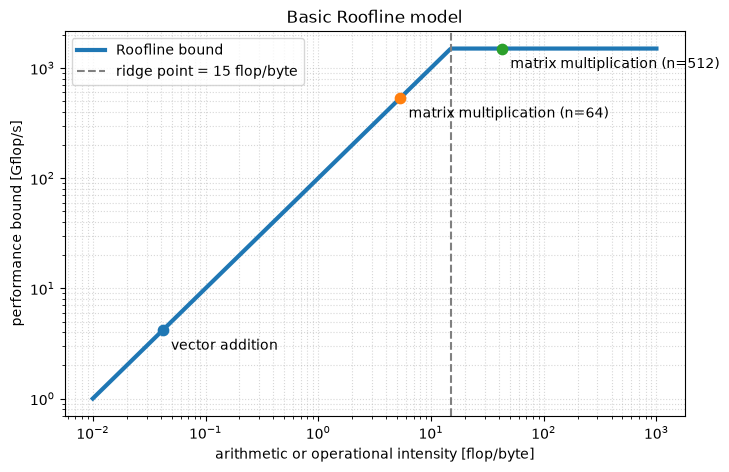

Ridge point: 15 flop/byte
kernel                            intensity          bound  limiting roof
vector addition                     0.04167        4.167 Gflop/s  memory bandwidth
matrix multiplication (n=64)          5.333        533.3 Gflop/s  memory bandwidth
matrix multiplication (n=512)         42.67         1500 Gflop/s  arithmetic


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def plot_roofline(peak_gflops, bandwidth_gbs, matrix_sizes):
    def ideal_matmul_intensity(n):
        return (2 * n**3) / (3 * n**2 * 8)

    kernels = {"vector addition": 1 / 24}
    kernels.update({
        f"matrix multiplication (n={n})": ideal_matmul_intensity(n)
        for n in matrix_sizes
    })

    ridge_intensity = peak_gflops / bandwidth_gbs
    kernel_bounds = {
        name: min(peak_gflops, bandwidth_gbs * intensity)
        for name, intensity in kernels.items()
    }

    all_i = [ridge_intensity, *kernels.values()]
    x_min = 10 ** np.floor(np.log10(min(all_i) / 3))
    x_max = 10 ** np.ceil(np.log10(max(all_i) * 3))
    x = np.logspace(np.log10(x_min), np.log10(x_max), 400)
    roof = np.minimum(peak_gflops, bandwidth_gbs * x)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.loglog(x, roof, linewidth=3, label="Roofline bound")
    ax.axvline(ridge_intensity, color="0.5", linestyle="--",
               label=f"ridge point = {ridge_intensity:g} flop/byte")
    for name, intensity in kernels.items():
        bound = kernel_bounds[name]
        ax.scatter(intensity, bound, s=55, zorder=3)
        ax.annotate(name, (intensity, bound), xytext=(6, -14),
                    textcoords="offset points")
    ax.set_xlabel("arithmetic or operational intensity [flop/byte]")
    ax.set_ylabel("performance bound [Gflop/s]")
    ax.set_title("Basic Roofline model")
    ax.grid(True, which="both", linestyle=":", alpha=0.5)
    ax.legend()
    plt.show()

    print(f"Ridge point: {ridge_intensity:g} flop/byte")
    print(f"{'kernel':30s} {'intensity':>12s} {'bound':>14s}  limiting roof")
    for name, intensity in kernels.items():
        roof_name = "memory bandwidth" if intensity < ridge_intensity else "arithmetic"
        print(f"{name:30s} {intensity:12.4g} {kernel_bounds[name]:12.4g} Gflop/s  {roof_name}")

# decimal units: GB/s x flop/byte = Gflop/s
plot_roofline(peak_gflops=1500.0, bandwidth_gbs=100.0, matrix_sizes=[64, 512])

## Ripasso lampo

- **Roofline in una frase**: performance ≤ min(picco aritmetico, bandwidth × intensità).
- **Intensità**: flop utili per byte trasferito. Alta = computazionale, bassa = memory-bound.
- **Ridge** = $P_{\max}/B$ : macchina bilanciata quando un kernel la raggiunge.
- Matmul ideale: $I \approx n/12$ → la taglia conta, ma serve blocking per realizzarla.
- Ottimizzare = spostarsi **destra** (riuso) o **su** (vettorizzazione/parallelismo), mai inventare flop.
- Misura e raffina: bandwidth sostenuta (STREAM), un tetto per livello di cache, profiling per capire cosa limita davvero.